In [2]:
import sys
sys.path.append("scripts")

from shared import *

In [3]:
from collections import Counter, defaultdict
from matplotlib import pyplot as plt
import string
import tqdm
from unidecode import unidecode

In [4]:
QS = load_all_questions(folder="../data/splits")

In [5]:
AS_LLAMA3 = load_sampled_answers("../data/sampled_answers/llama3-8b")

In [6]:
QS[4101]

{'id': 4101,
 'split': 'train',
 'type': 'museum_founder',
 'question': 'Who founded the museum Castle of Sperlinga?',
 'answer': 'Giovanni Natoli'}

In [21]:
def normalize_ans(s):
    s = s.strip()
    s = unidecode(s)
    s = s.translate(string.punctuation)
    return s

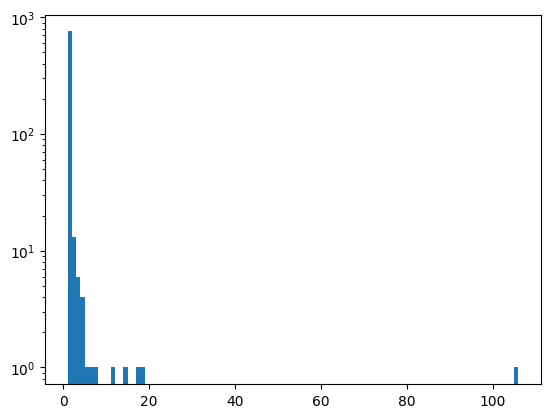

In [13]:
id = 4102
rs = [r["count"] for r in AS_LLAMA3[str(id)]["sampled"]]
plt.hist(rs, bins=range(min(rs), max(rs)+1))
plt.yscale("log")

In [14]:
multi_sampled_cts = [len([r for r in AS_LLAMA3[str(id)]["sampled"] if r["count"] > 1]) for id in tqdm.tqdm(range(7500))]

100%|█████████████████████████████████████████████████████████████| 7500/7500 [00:14<00:00, 500.07it/s]


(array([ 466., 1277., 1564., 1560., 1185.,  750.,  384.,  204.,   91.,
          19.]),
 array([  2. ,  14.2,  26.4,  38.6,  50.8,  63. ,  75.2,  87.4,  99.6,
        111.8, 124. ]),
 <BarContainer object of 10 artists>)

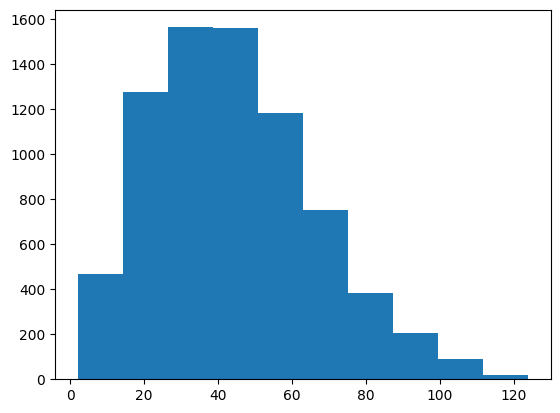

In [15]:
plt.hist(multi_sampled_cts)

In [22]:
train_sampled_by_cat = defaultdict(lambda: Counter())

for id in tqdm.tqdm(range(7500)):
    if not QS[id]["split"] == "train":
        continue
    # ans = normalize_ans(QS[id]["answer"])
    sampled_ans = set([normalize_ans(a["text"]) for a in AS_LLAMA3[str(id)]["sampled"]])
    train_sampled_by_cat[QS[id]["type"]].update(sampled_ans)

100%|█████████████████████████████████████████████████████████████| 7500/7500 [00:11<00:00, 655.46it/s]


In [24]:
for k in train_sampled_by_cat:
    print(k)
    for sampled_ans, n in train_sampled_by_cat[k].most_common()[:20]:
        print(n, sampled_ans.strip())
    print("")

spouse
90 John
63 Mark Zuckerberg
56 Barbara
51 Sarah
46 Elizabeth
46 Abraham Lincoln
41 Elizabeth Taylor
40 Michael
39 Elon Musk
39 ```
38 George
35 Donald Trump
35 Robert
34 David
33 Oprah Winfrey
31 Obama
31 Winston Churchill
30 Nelson Rockefeller
30 Elton John
30 Charles

manufacturer
158 Samsung
142 Apple
135 Microsoft
105 Samsung Electronics
105 Sony
104 Acer
97 Nokia
96 IBM
89 Amazon
88 HTC
82 Panasonic
79 LG Electronics
74 Google
73 Nintendo
73 Asus
70 Lenovo
69 Microsoft Corporation
66 AMD
65 Facebook
63 Motorola

record_label
190 A&M Records
157 Epic Records
150 Virgin Records
142 Warner Bros. Records
139 RCA Records
136 Atlantic Records
133 Polydor Records
129 Motown Records
129 Warner Bros. Records.
124 Decca Records
117 Blue Note Records
115 Geffen Records
109 MCA Records
99 Warner Music Group
98 Metal Blade Records
95 Elektra Records
95 Parlophone
94 Parlophone Records
94 EMI Records
93 Warner Music Group.

author
76 Kafka
64 Gunter Grass
58 Agatha Christie
56 Salman Rush

In [20]:
correct_sampled = []
all_sampled_by_cat = defaultdict(lambda: Counter())

for id in tqdm.tqdm(range(7500)):
    if not QS[id]["split"] == "train":
        continue
    ans = normalize_ans(QS[id]["answer"])
    sampled_ans = set([normalize_ans(a["text"]) for a in AS_LLAMA3[str(id)]["sampled"]])
    all_sampled_by_cat[QS[id]["type"]].update(sampled_ans)
    if ans in sampled_ans:
        correct_sampled.append(id)

100%|█████████████████████████████████████████████████████████████| 7500/7500 [00:20<00:00, 359.87it/s]


In [15]:
len(correct_sampled)
correct_sampled_by_cat = Counter([QS[id]["type"] for id in correct_sampled])

for cat, k in correct_sampled_by_cat.most_common():
    print(k, cat)

82 manufacturer
72 deathcity
69 enterprise_foundcity
63 business_foundcity
62 enterprise_hq
53 business_hq
53 birthcity
38 brand_owner
20 producer
18 record_label
17 author
16 business_founder
11 director_photography
11 museum_founder
10 enterprise_founder
3 spouse
3 film_editor
3 costume_designer
2 production_designer


In [21]:
for entity, k in all_sampled_by_cat["spouse"].most_common():
    print(k, entity)

182 John
114 Barbara
111 Mark Zuckerberg
104 Sarah
101 Michael
94 Elizabeth
90 Abraham Lincoln
79 ```
77 David
75 George
74 Elizabeth Taylor
72 Elon Musk
70 Donald Trump
69 Elton John
64 Winston Churchill
63 Ellen
63 Robert
63 Smith
61 Oprah Winfrey
61 Henry
58 Margaret
57 Mary
56 Diana Spencer
53 Charles
53 Anne
51 Helen
50 William
50 Nelson Rockefeller
50 Hillary Clinton
49 Obama
49 Elvis Presley
49 Peter
47 Diana
45 Elwes
44 Queen Elizabeth II
44 India Hicks
44 Harrison Ford
43 Arnold Schwarzenegger
43 Camilla Parker Bowles
42 George Clooney
42 Meg
41 Steve Jobs
40 Yoko Ono
39 Abigail Adams
39 Rupert Murdoch
39 Ellen DeGeneres
39 Richard
38 Elizabeth II
37 Nelson Mandela
37 Taylor Swift
37 Marilyn Monroe
37 Astrid
36 Gwyneth Paltrow
36 Steve
36 Beatrix Potter
35 Meryl Streep
35 Golda Meir
35 
35 Churchill
34 Stephen
34 Elizabeth II of the United Kingdom
34 Answer:
34 Anna
33 Jimi Hendrix
33 Maria
33 Jane
33 Nancy
33 Catherine
33 Australia
32 Bill
32 Kate
32 Malcolm Turnbull
32 Ruth


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)

